# Motor de Corrente Contínua
São equações do conversor eletromecânico de energia ideal:
* Tensão induzida nos terminais $e = k \phi \omega$
* Torque induzido no eixo $T_{\rm{motor}} = k \phi i$


A equação que rege o comportamento elétrico do MCC é dada por
$$ \sum V = 0 $$
$$ v - Ri - L\frac{di}{dt} - k \phi \omega = 0 $$

# Carga Mecânica
A equação quer rege o comportamenteo do cricuito mecâncio é dada por
$$ \sum T = J \alpha $$
$$ J \frac{d \omega}{dt} = k \phi i- B \omega - \tau_{\rm{carga}} $$

In [ ]:
import sympy as sp
sp.init_printing()

In [ ]:
t = sp.Symbol('t', real=True, positive=True)
s = sp.Symbol('s')

In [ ]:
a = sp.Symbol('alpha', real=True, positive=True)
b = sp.Rational(1, 10)#sp.Symbol('beta', real=True, positive=True)
V = 120#sp.Symbol('V', real=True, positive=True)
R = sp.Rational(1, 10)#sp.Symbol('R', real=True, positive=True)
L = sp.Rational(5, 10)#sp.Symbol('L', real=True, positive=True)
J = sp.Rational(23, 10)#sp.Symbol('L', real=True, positive=True)
k = 1#sp.Symbol('k', real=True, positive=True)
f = sp.Rational(25, 100)#sp.Symbol('phi', real=True, positive=True)
i0 = 0#sp.Symbol('i_0', real=True)
w0 = 0#sp.Symbol('omega_0', real=True)

In [ ]:
I = sp.Function("I")(s)
W = sp.Function("Omega")(s)
Tcarga = b * W

In [ ]:
EQ1 = sp.Eq(V/s - R*I - L*(s*I-i0) - k*f*W , 0)
EQ2 = sp.Eq(k*f*I - b * W , J*(s*W - w0))
EQ = sp.Matrix([[EQ1], [EQ2]])
sp.latex(EQ)

'\\left[\\begin{matrix}- \\frac{s I{\\left(s \\right)}}{2} - \\frac{I{\\left(s \\right)}}{10} - \\frac{\\Omega{\\left(s \\right)}}{4} + \\frac{120}{s} = 0\\\\\\frac{I{\\left(s \\right)}}{4} - \\frac{\\Omega{\\left(s \\right)}}{10} = \\frac{23 s \\Omega{\\left(s \\right)}}{10}\\end{matrix}\\right]'

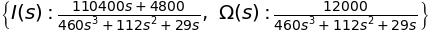

In [ ]:
SOL = sp.solve( EQ, sp.Matrix([[I],[W]]) )
SOL

In [ ]:
II = sp.apart(SOL[I])
sp.latex(II)

'- \\frac{24000 \\left(92 s - 111\\right)}{29 \\left(460 s^{2} + 112 s + 29\\right)} + \\frac{4800}{29 s}'

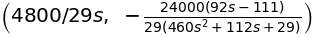

In [ ]:
II.args

In [ ]:
temp1 = sp.inverse_laplace_transform(II.args[0], s, t)
temp2 = sp.inverse_laplace_transform(II.args[1], s, t)

In [ ]:
i = temp1 + temp2
i

In [ ]:
WW = sp.apart(SOL[W])
sp.latex(WW)

'- \\frac{48000 \\left(115 s + 28\\right)}{29 \\left(460 s^{2} + 112 s + 29\\right)} + \\frac{12000}{29 s}'

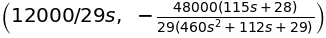

In [ ]:
WW.args

In [ ]:
temp1 = sp.inverse_laplace_transform(WW.args[0], s, t)
temp2 = sp.inverse_laplace_transform(WW.args[1], s, t)

In [ ]:
w = temp1 + temp2
w

In [ ]:
iFunc = sp.lambdify(t, i)
wFunc = sp.lambdify(t, w)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
tNum = np.linspace(0, 100, 1000)

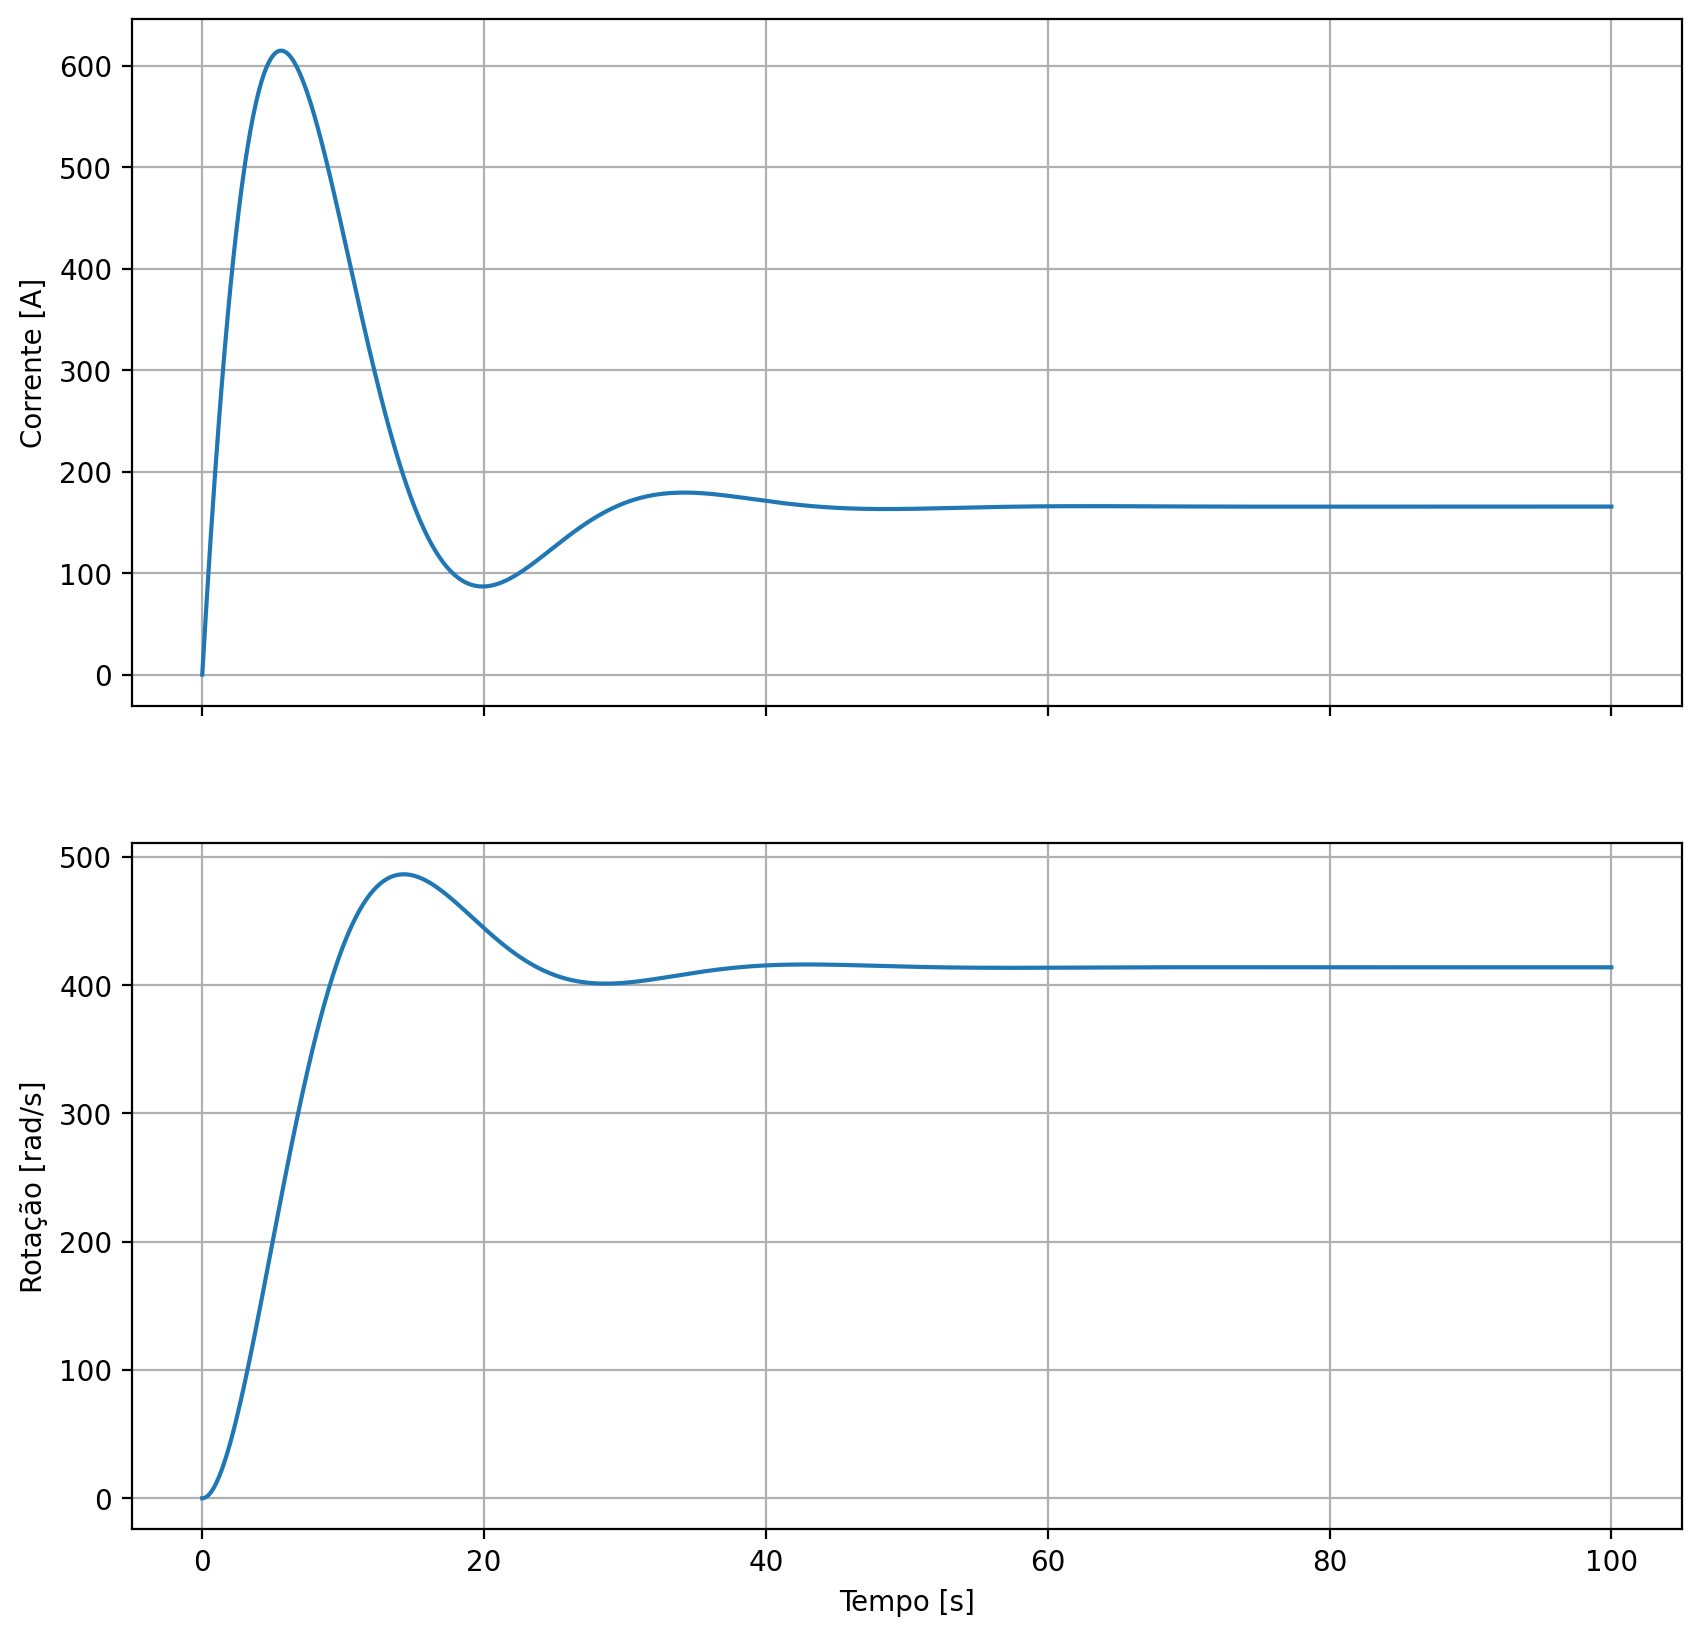

In [ ]:
fig, (ax0, ax1) = plt.subplots(2, 1, sharex=True, figsize=(10,10), dpi=200)
ax0.plot(tNum, iFunc(tNum))
ax1.plot(tNum, wFunc(tNum))
ax1.set_xlabel("Tempo [s]")
ax0.set_ylabel("Corrente [A]")
ax1.set_ylabel("Rotação [rad/s]")
ax1.grid()
ax0.grid()
fig.show()